# XGBoost 80/20 results analysis

This notebook analyzes the `results_xgb/*.h5` files produced by the **new 80/20 XGBoost pipeline**.

It will:

- scan all saved protein H5 files,
- print completion and coverage checks,
- summarize test-set MSE, Pearson correlation, and cosine similarity,
- compare normalizations,
- count how many proteins pass configurable performance thresholds,
- pick the best normalization/model per protein,
- inspect one saved model artifact without loading every model into memory.

Run this notebook from the project root, at the same level as `run_xgboost.sh`, `src/`, `data/`, and `results_xgb/`.

In [1]:
from pathlib import Path
import json
import re
import sys
import math
import warnings

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Project layout
PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results_xgb"
DATA_DIR = PROJECT_DIR / "data"
SRC_DIR = PROJECT_DIR / "src"

print("PROJECT_DIR:", PROJECT_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:", DATA_DIR)
print("SRC_DIR:", SRC_DIR)

assert RESULTS_DIR.exists(), f"Missing results directory: {RESULTS_DIR}"
assert SRC_DIR.exists(), f"Missing src directory: {SRC_DIR}"

PROJECT_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb
RESULTS_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\results_xgb
DATA_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\data
SRC_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\src


## Configuration

Adjust these thresholds to define what “predicted well” means for your analysis.

Because MSE is scale-dependent, the notebook uses Pearson and cosine thresholds as the main interpretable cutoffs, and also reports MSE quantiles. A row can optionally be marked “good” only if it also has MSE below a chosen quantile within each normalization.

In [2]:
# Expected full-run settings. Change if you used a different run.
EXPECTED_NORMALIZATIONS = ["none", "zscore", "rank", "qbin50"]
EXPECTED_SELECT_K = 2000
EXPECTED_GRID = "fast"

# Main thresholds for "good prediction" on internal 20% test set.
GOOD_PEARSON = 0.30
STRONG_PEARSON = 0.50
EXCELLENT_PEARSON = 0.70

GOOD_COSINE = 0.30
STRONG_COSINE = 0.50
EXCELLENT_COSINE = 0.70

# Optional MSE criterion. Since MSE scale depends on the target protein,
# this uses a within-normalization quantile instead of a fixed MSE value.
USE_MSE_QUANTILE_FOR_GOOD = False
GOOD_MSE_QUANTILE = 0.50   # lower is stricter; 0.50 means below median MSE per normalization

# Ranking score weights for choosing a balanced best result per protein.
# Pearson and cosine are higher-is-better; MSE is lower-is-better.
SCORE_WEIGHTS = {
    "pearson": 0.55,
    "cosine": 0.25,
    "mse": 0.20,
}

TOP_N_TO_DISPLAY = 25

print("Good Pearson threshold:", GOOD_PEARSON)
print("Good cosine threshold:", GOOD_COSINE)
print("Use MSE quantile in good flag:", USE_MSE_QUANTILE_FOR_GOOD)
print("Expected normalizations:", EXPECTED_NORMALIZATIONS)

Good Pearson threshold: 0.3
Good cosine threshold: 0.3
Use MSE quantile in good flag: False
Expected normalizations: ['none', 'zscore', 'rank', 'qbin50']


## Load H5 summaries

This reads only the lightweight summary parts of each H5 file. It does **not** load every XGBoost model artifact into memory.

In [3]:
FILENAME_RE = re.compile(
    r"^(?P<protein>.+)_xgb_8020_(?P<normalization>none|zscore|rank|qbin[0-9]+)_(?P<grid>tiny|fast|current)_k(?P<select_k>[0-9]+)\.h5$"
)

def parse_filename(path: Path):
    m = FILENAME_RE.match(path.name)
    if not m:
        return {
            "protein_from_filename": None,
            "normalization": None,
            "grid": None,
            "select_k": np.nan,
            "filename_parse_ok": False,
        }
    d = m.groupdict()
    return {
        "protein_from_filename": d["protein"],
        "normalization": d["normalization"],
        "grid": d["grid"],
        "select_k": int(d["select_k"]),
        "filename_parse_ok": True,
    }


def bytes_to_json(byte_array):
    return json.loads(bytes(byte_array).decode("utf-8"))


def decode_bytes_array(arr):
    out = []
    for x in arr:
        if isinstance(x, bytes):
            out.append(x.decode("utf-8"))
        else:
            out.append(str(x))
    return out


def read_h5_summary(path: Path):
    info = parse_filename(path)
    row = {
        "h5_path": str(path),
        "file": path.name,
        "file_size_mb": path.stat().st_size / (1024 ** 2),
        "modified_time": pd.to_datetime(path.stat().st_mtime, unit="s"),
        **info,
    }

    try:
        with h5py.File(path, "r") as h5:
            row["format"] = h5.attrs.get("format", "")
            row["protein"] = str(h5.attrs.get("protein", info.get("protein_from_filename") or ""))
            row["model_kind"] = str(h5.attrs.get("model_kind", ""))

            # Metric attrs are quick and reliable.
            metrics_group = h5.get("metrics")
            if metrics_group is not None:
                row["test_mse"] = float(metrics_group.attrs.get("test_mse", np.nan))
                row["test_pearson_corr"] = float(metrics_group.attrs.get("test_pearson_corr", np.nan))
                row["test_cosine_similarity"] = float(metrics_group.attrs.get("test_cosine_similarity", np.nan))

                if "summary_json" in metrics_group:
                    summary = bytes_to_json(metrics_group["summary_json"][:])
                    row["summary_json_ok"] = True
                    row["n_train_samples"] = len(summary.get("train_samples", []))
                    row["n_test_samples"] = len(summary.get("test_samples", []))
                    row["n_selected_features_json"] = len(summary.get("selected_features", []))
                    row["model_note"] = summary.get("model_note", "")
                    row["best_params"] = summary.get("best_params", {})
                else:
                    row["summary_json_ok"] = False

            samples_group = h5.get("samples")
            if samples_group is not None:
                if "train_samples" in samples_group:
                    row["n_train_samples"] = len(samples_group["train_samples"])
                if "test_samples" in samples_group:
                    row["n_test_samples"] = len(samples_group["test_samples"])

            model_group = h5.get("model")
            if model_group is not None:
                row["artifact_kind"] = str(model_group.attrs.get("artifact_kind", ""))
                row["selected_feature_count"] = int(model_group.attrs.get("selected_feature_count", -1))
                if "best_params_json" in model_group:
                    try:
                        row["best_params"] = bytes_to_json(model_group["best_params_json"][:])
                    except Exception:
                        pass

    except Exception as e:
        row["read_error"] = f"{type(e).__name__}: {e}"

    return row


h5_files = sorted(RESULTS_DIR.glob("*.h5"))
print(f"Found {len(h5_files):,} H5 files in {RESULTS_DIR}")

rows = [read_h5_summary(p) for p in h5_files]
df = pd.DataFrame(rows)

if df.empty:
    raise RuntimeError("No .h5 result files found. Check RESULTS_DIR or wait for the cluster job to produce outputs.")

# Ensure expected columns exist even if some files failed to parse.
for col in ["test_mse", "test_pearson_corr", "test_cosine_similarity", "selected_feature_count", "n_train_samples", "n_test_samples"]:
    if col not in df.columns:
        df[col] = np.nan
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Prefer protein from H5 attrs, fallback to filename.
df["protein"] = df["protein"].fillna(df.get("protein_from_filename"))

print("Rows loaded:", len(df))
print("Unique proteins:", df["protein"].nunique())
print("Normalizations detected:", sorted(df["normalization"].dropna().unique()))
print("Files with read errors:", df.get("read_error", pd.Series(dtype=object)).notna().sum())

display(df.head())

Found 5,113 H5 files in c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\results_xgb
Rows loaded: 5113
Unique proteins: 5113
Normalizations detected: ['zscore']
Files with read errors: 0


,h5_path,file,file_size_mb,modified_time,protein_from_filename,normalization,grid,select_k,filename_parse_ok,format,...,test_pearson_corr,test_cosine_similarity,summary_json_ok,n_train_samples,n_test_samples,n_selected_features_json,model_note,best_params,artifact_kind,selected_feature_count
0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_zscore_current_k5000.h5,0.381228,2026-05-20 06:07:18.890078068,A2M,zscore,current,5000,True,minimal_8020_xgboost_h5,...,0.475142,0.565068,True,295,74,5000,Final model is trained on all Dataset 1 sample...,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",final_all_samples_model_after_80_20_evaluation,5000
1,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,AAAS_xgb_8020_zscore_current_k5000.h5,0.322832,2026-05-20 06:07:19.242333889,AAAS,zscore,current,5000,True,minimal_8020_xgboost_h5,...,0.418940,0.439933,True,295,74,5000,Final model is trained on all Dataset 1 sample...,"{'colsample_bytree': 1.0, 'device': 'cpu', 'ga...",final_all_samples_model_after_80_20_evaluation,5000
2,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,AACS_xgb_8020_zscore_current_k5000.h5,0.354722,2026-05-20 06:07:19.864425421,AACS,zscore,current,5000,True,minimal_8020_xgboost_h5,...,0.521467,0.518639,True,295,74,5000,Final model is trained on all Dataset 1 sample...,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",final_all_samples_model_after_80_20_evaluation,5000
3,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,AAGAB_xgb_8020_zscore_current_k5000.h5,0.330355,2026-05-20 06:07:20.513252735,AAGAB,zscore,current,5000,True,minimal_8020_xgboost_h5,...,0.393959,0.394048,True,295,74,5000,Final model is trained on all Dataset 1 sample...,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",final_all_samples_model_after_80_20_evaluation,5000
4,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,AAK1_xgb_8020_zscore_current_k5000.h5,0.316789,2026-05-20 06:07:21.085634232,AAK1,zscore,current,5000,True,minimal_8020_xgboost_h5,...,0.665431,0.670005,True,295,74,5000,Final model is trained on all Dataset 1 sample...,"{'colsample_bytree': 1.0, 'device': 'cpu', 'ga...",final_all_samples_model_after_80_20_evaluation,5000


## Completion and coverage checks

This section checks how many files exist by normalization, and optionally compares against the protein list in `data/proteomics_matched.joblib`.

In [4]:
# Basic coverage by normalization
coverage = (
    df.groupby("normalization", dropna=False)
      .agg(
          files=("file", "count"),
          proteins=("protein", "nunique"),
          median_file_mb=("file_size_mb", "median"),
          min_mtime=("modified_time", "min"),
          max_mtime=("modified_time", "max"),
      )
      .sort_index()
)

display(Markdown("### Files and proteins by normalization"))
display(coverage)

# Try to detect expected proteins from data if the data files are present.
expected_proteins = None
try:
    from joblib import load
    X = load(DATA_DIR / "transcriptomics_filtered.joblib")
    Y = load(DATA_DIR / "proteomics_matched.joblib")
    x_samples = pd.Index(map(str, X.index))
    y_index = pd.Index(map(str, Y.index))
    y_columns = pd.Index(map(str, Y.columns))
    index_overlap = len(x_samples.intersection(y_index))
    column_overlap = len(x_samples.intersection(y_columns))
    expected_proteins = list(map(str, Y.columns if index_overlap >= column_overlap else Y.index))
    print(f"Detected {len(expected_proteins):,} expected proteins from data files.")
    print("First expected proteins:", expected_proteins[:5])
except Exception as e:
    print("Could not load data files to check expected proteins:", repr(e))

if expected_proteins is not None:
    expected = pd.MultiIndex.from_product(
        [expected_proteins, EXPECTED_NORMALIZATIONS],
        names=["protein", "normalization"],
    ).to_frame(index=False)
    observed = df[["protein", "normalization"]].drop_duplicates()
    missing = expected.merge(observed, on=["protein", "normalization"], how="left", indicator=True)
    missing = missing[missing["_merge"] == "left_only"].drop(columns="_merge")

    print(f"Expected files for configured normalizations: {len(expected):,}")
    print(f"Observed protein-normalization pairs: {len(observed):,}")
    print(f"Missing protein-normalization pairs: {len(missing):,}")

    missing_by_norm = missing.groupby("normalization").size().rename("missing_files").reset_index()
    display(Markdown("### Missing outputs by normalization"))
    display(missing_by_norm)

    if len(missing) > 0:
        display(Markdown("### First missing outputs"))
        display(missing.head(30))

### Files and proteins by normalization

,files,proteins,median_file_mb,min_mtime,max_mtime
normalization,,,,,
zscore,5113,5113,0.326234,2026-05-20 06:07:18.520244359,2026-05-20 06:14:59.343473911


Could not load data files to check expected proteins: FileNotFoundError(2, 'No such file or directory')


## Metric summary

Pearson correlation and cosine similarity are higher-is-better. MSE is lower-is-better.

In [5]:
metric_cols = ["test_pearson_corr", "test_cosine_similarity", "test_mse"]
valid_df = df.dropna(subset=["normalization", "protein"]).copy()

summary_by_norm = (
    valid_df.groupby("normalization")
    .agg(
        n=("protein", "count"),
        proteins=("protein", "nunique"),
        pearson_mean=("test_pearson_corr", "mean"),
        pearson_median=("test_pearson_corr", "median"),
        pearson_q25=("test_pearson_corr", lambda s: s.quantile(0.25)),
        pearson_q75=("test_pearson_corr", lambda s: s.quantile(0.75)),
        cosine_mean=("test_cosine_similarity", "mean"),
        cosine_median=("test_cosine_similarity", "median"),
        mse_median=("test_mse", "median"),
        mse_q25=("test_mse", lambda s: s.quantile(0.25)),
        mse_q75=("test_mse", lambda s: s.quantile(0.75)),
        selected_features_median=("selected_feature_count", "median"),
        train_samples_median=("n_train_samples", "median"),
        test_samples_median=("n_test_samples", "median"),
    )
    .sort_values(["pearson_median", "cosine_median"], ascending=False)
)

display(Markdown("### Summary by normalization"))
display(summary_by_norm)

# Overall summary
print("Overall rows:", len(valid_df))
print("Overall unique proteins:", valid_df["protein"].nunique())
print("Pearson median:", valid_df["test_pearson_corr"].median())
print("Cosine median:", valid_df["test_cosine_similarity"].median())
print("MSE median:", valid_df["test_mse"].median())

### Summary by normalization

,n,proteins,pearson_mean,pearson_median,pearson_q25,pearson_q75,cosine_mean,cosine_median,mse_median,mse_q25,mse_q75,selected_features_median,train_samples_median,test_samples_median
normalization,,,,,,,,,,,,,,
zscore,5113,5113,0.533425,0.534373,0.412087,0.662463,0.539087,0.538041,0.271998,0.198127,0.397155,5000.0,295.0,74.0


Overall rows: 5113
Overall unique proteins: 5113
Pearson median: 0.5343726488074336
Cosine median: 0.5380414921423496
MSE median: 0.2719982704587481


## Threshold counts: how many proteins are predicted well?

The main “good” flag is configurable near the top of the notebook.

Default definition:

```text
Pearson >= 0.30 AND cosine similarity >= 0.30
```

If `USE_MSE_QUANTILE_FOR_GOOD=True`, a row must also have MSE below the configured within-normalization MSE quantile.

In [6]:
work = valid_df.copy()

# Within-normalization MSE cutoff so each normalization is judged against its own MSE scale.
work["mse_cutoff_by_norm"] = work.groupby("normalization")["test_mse"].transform(lambda s: s.quantile(GOOD_MSE_QUANTILE))
work["mse_pass_quantile"] = work["test_mse"] <= work["mse_cutoff_by_norm"]

work["good_pearson"] = work["test_pearson_corr"] >= GOOD_PEARSON
work["strong_pearson"] = work["test_pearson_corr"] >= STRONG_PEARSON
work["excellent_pearson"] = work["test_pearson_corr"] >= EXCELLENT_PEARSON

work["good_cosine"] = work["test_cosine_similarity"] >= GOOD_COSINE
work["strong_cosine"] = work["test_cosine_similarity"] >= STRONG_COSINE
work["excellent_cosine"] = work["test_cosine_similarity"] >= EXCELLENT_COSINE

if USE_MSE_QUANTILE_FOR_GOOD:
    work["predicted_well"] = work["good_pearson"] & work["good_cosine"] & work["mse_pass_quantile"]
else:
    work["predicted_well"] = work["good_pearson"] & work["good_cosine"]

threshold_summary = (
    work.groupby("normalization")
    .agg(
        n=("protein", "count"),
        good_pearson=("good_pearson", "sum"),
        strong_pearson=("strong_pearson", "sum"),
        excellent_pearson=("excellent_pearson", "sum"),
        good_cosine=("good_cosine", "sum"),
        strong_cosine=("strong_cosine", "sum"),
        excellent_cosine=("excellent_cosine", "sum"),
        predicted_well=("predicted_well", "sum"),
    )
)

for col in ["good_pearson", "strong_pearson", "excellent_pearson", "good_cosine", "strong_cosine", "excellent_cosine", "predicted_well"]:
    threshold_summary[col + "_%"] = 100 * threshold_summary[col] / threshold_summary["n"]

threshold_summary = threshold_summary.sort_values("predicted_well_%", ascending=False)

display(Markdown("### Threshold summary by normalization"))
display(threshold_summary)

print("Good prediction definition:")
print(f"  test_pearson_corr >= {GOOD_PEARSON}")
print(f"  test_cosine_similarity >= {GOOD_COSINE}")
if USE_MSE_QUANTILE_FOR_GOOD:
    print(f"  test_mse <= within-normalization quantile {GOOD_MSE_QUANTILE}")
else:
    print("  MSE criterion disabled; inspect MSE quantiles separately.")

print("Total predicted-well rows:", int(work["predicted_well"].sum()), "out of", len(work))
print("Proteins with at least one predicted-well normalization:", work.loc[work["predicted_well"], "protein"].nunique())

### Threshold summary by normalization

,n,good_pearson,strong_pearson,excellent_pearson,good_cosine,strong_cosine,excellent_cosine,predicted_well,good_pearson_%,strong_pearson_%,excellent_pearson_%,good_cosine_%,strong_cosine_%,excellent_cosine_%,predicted_well_%
normalization,,,,,,,,,,,,,,,
zscore,5113,4628,2917,966,4707,2978,976,4612,90.514375,57.050655,18.893018,92.059456,58.243693,19.088598,90.201447


Good prediction definition:
  test_pearson_corr >= 0.3
  test_cosine_similarity >= 0.3
  MSE criterion disabled; inspect MSE quantiles separately.
Total predicted-well rows: 4612 out of 5113
Proteins with at least one predicted-well normalization: 4612


## Best result per protein

The notebook provides two rankings:

1. **Best by Pearson**: highest test Pearson, tie-broken by lower MSE.
2. **Balanced score**: combines Pearson, cosine, and MSE percentile ranks.

Use Pearson ranking when your primary target is correlation. Use balanced score if you want to avoid choosing models with good correlation but poor MSE/cosine.

In [7]:
ranked = work.copy()

# Percentile-style scores across all rows.
ranked["pearson_score"] = ranked["test_pearson_corr"].rank(pct=True, ascending=True)
ranked["cosine_score"] = ranked["test_cosine_similarity"].rank(pct=True, ascending=True)
ranked["mse_score"] = ranked["test_mse"].rank(pct=True, ascending=False)  # lower MSE gets higher score

ranked["balanced_score"] = (
    SCORE_WEIGHTS["pearson"] * ranked["pearson_score"]
    + SCORE_WEIGHTS["cosine"] * ranked["cosine_score"]
    + SCORE_WEIGHTS["mse"] * ranked["mse_score"]
)

best_by_pearson = (
    ranked.sort_values(["protein", "test_pearson_corr", "test_mse"], ascending=[True, False, True])
    .groupby("protein", as_index=False)
    .head(1)
    .sort_values("test_pearson_corr", ascending=False)
)

best_by_score = (
    ranked.sort_values(["protein", "balanced_score", "test_pearson_corr"], ascending=[True, False, False])
    .groupby("protein", as_index=False)
    .head(1)
    .sort_values("balanced_score", ascending=False)
)

print("Proteins with at least one result:", ranked["protein"].nunique())
print("Best-by-Pearson rows:", len(best_by_pearson))
print("Best-by-score rows:", len(best_by_score))

best_cols = [
    "protein", "normalization", "test_pearson_corr", "test_cosine_similarity", "test_mse",
    "predicted_well", "balanced_score", "selected_feature_count", "n_train_samples", "n_test_samples", "h5_path"
]

display(Markdown(f"### Top {TOP_N_TO_DISPLAY} proteins by test Pearson"))
display(best_by_pearson[best_cols].head(TOP_N_TO_DISPLAY))

display(Markdown(f"### Top {TOP_N_TO_DISPLAY} proteins by balanced score"))
display(best_by_score[best_cols].head(TOP_N_TO_DISPLAY))

Proteins with at least one result: 5113
Best-by-Pearson rows: 5113
Best-by-score rows: 5113


### Top 25 proteins by test Pearson

,protein,normalization,test_pearson_corr,test_cosine_similarity,test_mse,predicted_well,balanced_score,selected_feature_count,n_train_samples,n_test_samples,h5_path
2016,IGF2BP1,zscore,0.928581,0.929066,0.368505,True,0.858400,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
164,ALDH1A1,zscore,0.918945,0.915131,0.621630,True,0.816184,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2363,MAP1B,zscore,0.914346,0.915567,0.369103,True,0.857901,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2069,IQGAP2,zscore,0.911325,0.907826,0.345181,True,0.865089,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
579,CAMK2D,zscore,0.905687,0.904005,0.246606,True,0.914688,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2209,LAD1,zscore,0.901220,0.900610,0.618535,True,0.815715,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
1233,DPYSL3,zscore,0.899462,0.901332,0.541302,True,0.823049,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3497,PTK7,zscore,0.895214,0.895234,0.339174,True,0.866927,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2458,MET,zscore,0.893045,0.892214,0.422294,True,0.841453,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
1403,ERAP2,zscore,0.890991,0.884741,0.594521,True,0.817094,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


### Top 25 proteins by balanced score

,protein,normalization,test_pearson_corr,test_cosine_similarity,test_mse,predicted_well,balanced_score,selected_feature_count,n_train_samples,n_test_samples,h5_path
1393,EPN2,zscore,0.844067,0.844227,0.187461,True,0.940514,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2349,MAGI1,zscore,0.850259,0.847401,0.197044,True,0.937385,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
4981,WHSC1L1,zscore,0.799230,0.799007,0.129494,True,0.937170,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2289,LRCH1,zscore,0.823187,0.825529,0.176122,True,0.933953,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2105,ITSN2,zscore,0.766008,0.768938,0.087547,True,0.917074,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
579,CAMK2D,zscore,0.905687,0.904005,0.246606,True,0.914688,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
4094,SLC25A24,zscore,0.858505,0.859840,0.238658,True,0.912605,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
4060,SIPA1L3,zscore,0.802889,0.789224,0.179598,True,0.909662,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
4483,TFCP2,zscore,0.824131,0.820189,0.211422,True,0.908576,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3678,RDX,zscore,0.841279,0.841663,0.228965,True,0.907950,5000,295,74,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


## Plots: counts, distributions, and threshold performance

The plots below use Matplotlib defaults. They should work on HPC/Jupyter without extra plotting packages.

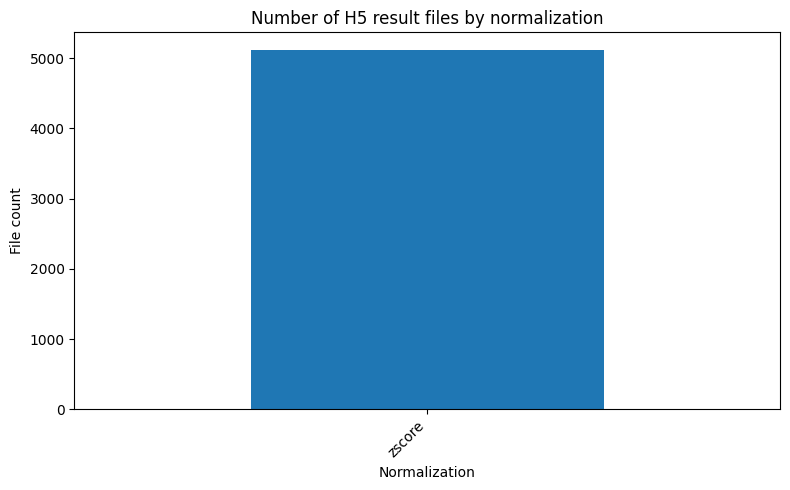

In [8]:
# Count by normalization
counts = work["normalization"].value_counts().sort_index()
plt.figure(figsize=(8, 5))
counts.plot(kind="bar")
plt.title("Number of H5 result files by normalization")
plt.xlabel("Normalization")
plt.ylabel("File count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

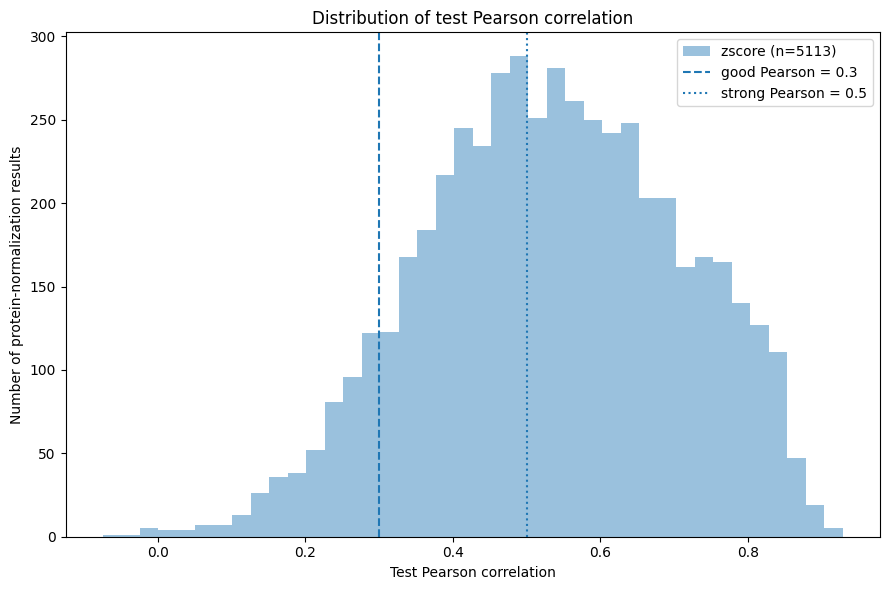

In [9]:
# Pearson histogram by normalization
plt.figure(figsize=(9, 6))
for norm, sub in work.groupby("normalization"):
    vals = sub["test_pearson_corr"].dropna()
    if len(vals) > 0:
        plt.hist(vals, bins=40, alpha=0.45, label=f"{norm} (n={len(vals)})")
plt.axvline(GOOD_PEARSON, linestyle="--", label=f"good Pearson = {GOOD_PEARSON}")
plt.axvline(STRONG_PEARSON, linestyle=":", label=f"strong Pearson = {STRONG_PEARSON}")
plt.title("Distribution of test Pearson correlation")
plt.xlabel("Test Pearson correlation")
plt.ylabel("Number of protein-normalization results")
plt.legend()
plt.tight_layout()
plt.show()

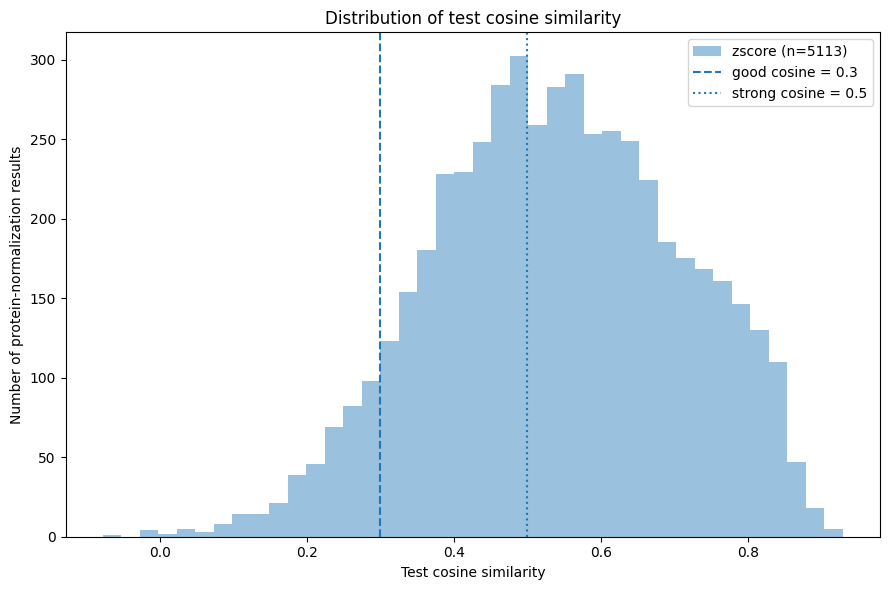

In [10]:
# Cosine histogram by normalization
plt.figure(figsize=(9, 6))
for norm, sub in work.groupby("normalization"):
    vals = sub["test_cosine_similarity"].dropna()
    if len(vals) > 0:
        plt.hist(vals, bins=40, alpha=0.45, label=f"{norm} (n={len(vals)})")
plt.axvline(GOOD_COSINE, linestyle="--", label=f"good cosine = {GOOD_COSINE}")
plt.axvline(STRONG_COSINE, linestyle=":", label=f"strong cosine = {STRONG_COSINE}")
plt.title("Distribution of test cosine similarity")
plt.xlabel("Test cosine similarity")
plt.ylabel("Number of protein-normalization results")
plt.legend()
plt.tight_layout()
plt.show()

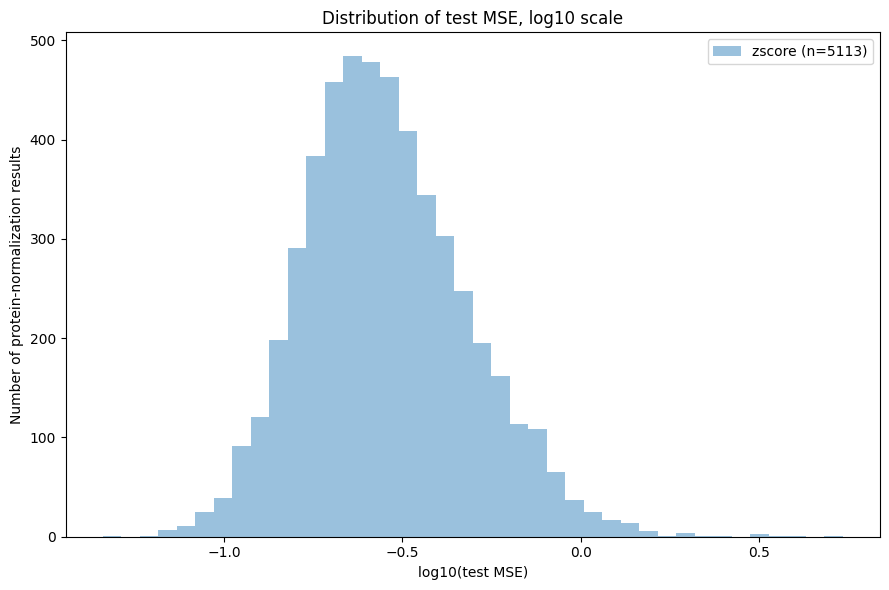

In [11]:
# MSE distribution on log scale
mse_vals = work["test_mse"].replace([np.inf, -np.inf], np.nan).dropna()
if len(mse_vals) > 0:
    plt.figure(figsize=(9, 6))
    for norm, sub in work.groupby("normalization"):
        vals = sub["test_mse"].replace([np.inf, -np.inf], np.nan).dropna()
        vals = vals[vals > 0]
        if len(vals) > 0:
            plt.hist(np.log10(vals), bins=40, alpha=0.45, label=f"{norm} (n={len(vals)})")
    plt.title("Distribution of test MSE, log10 scale")
    plt.xlabel("log10(test MSE)")
    plt.ylabel("Number of protein-normalization results")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No valid MSE values to plot.")

C:\Users\hp\AppData\Local\Temp\ipykernel_11104\3540114152.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=norm_order, showfliers=False)


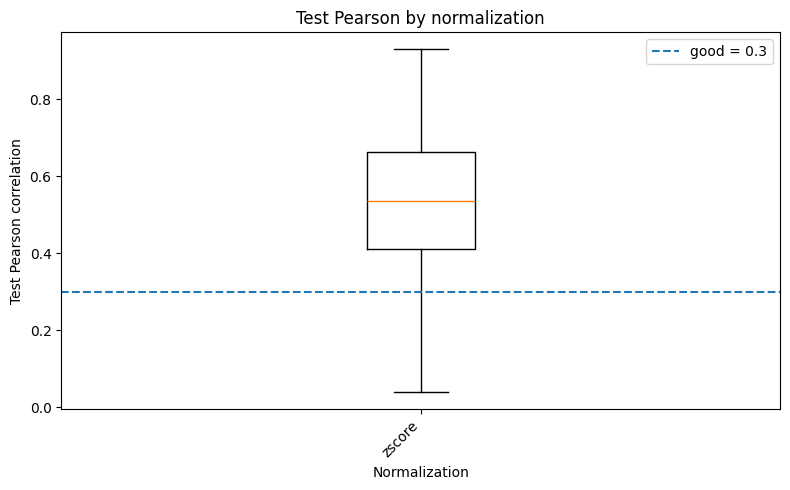

In [12]:
# Boxplot of Pearson by normalization
norm_order = sorted(work["normalization"].dropna().unique())
data = [work.loc[work["normalization"] == n, "test_pearson_corr"].dropna().values for n in norm_order]

plt.figure(figsize=(8, 5))
plt.boxplot(data, labels=norm_order, showfliers=False)
plt.axhline(GOOD_PEARSON, linestyle="--", label=f"good = {GOOD_PEARSON}")
plt.title("Test Pearson by normalization")
plt.xlabel("Normalization")
plt.ylabel("Test Pearson correlation")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

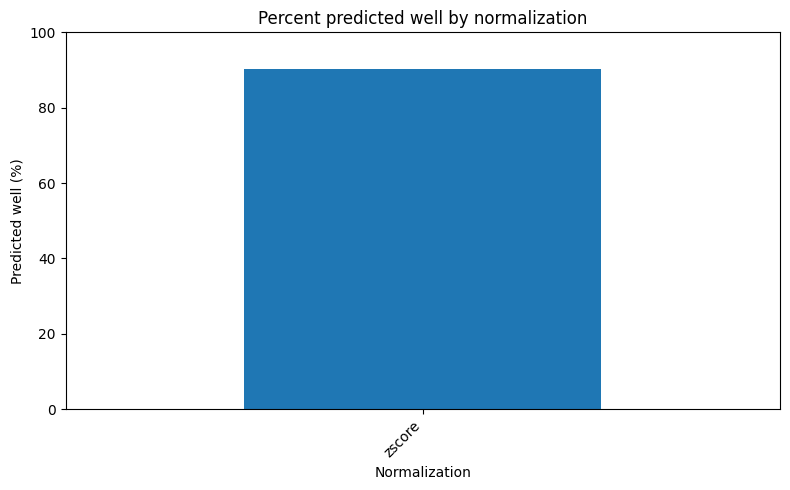

In [13]:
# Percentage predicted well by normalization
pred_well_pct = threshold_summary["predicted_well_%"].sort_values(ascending=False)
plt.figure(figsize=(8, 5))
pred_well_pct.plot(kind="bar")
plt.title("Percent predicted well by normalization")
plt.xlabel("Normalization")
plt.ylabel("Predicted well (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(5, min(100, pred_well_pct.max() * 1.15 if len(pred_well_pct) else 100)))
plt.tight_layout()
plt.show()

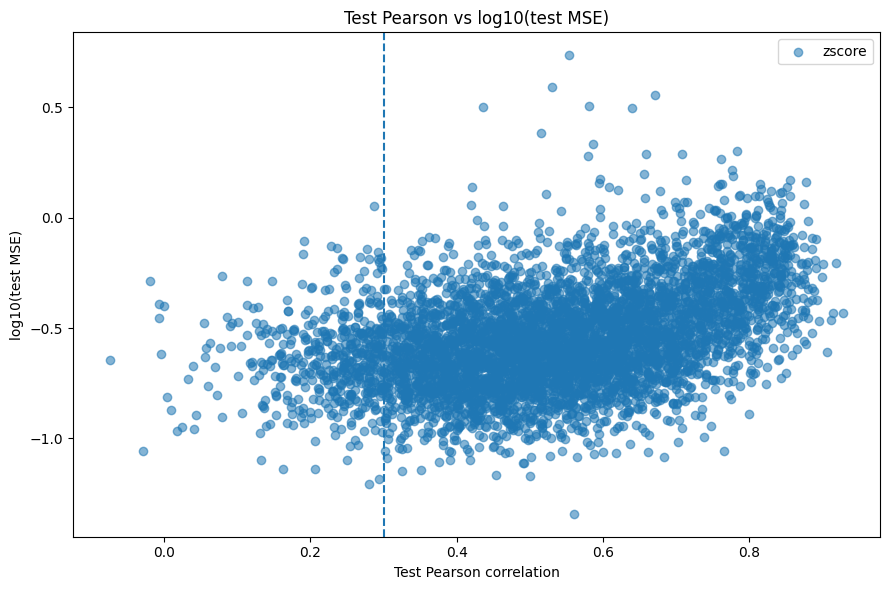

In [14]:
# Scatter Pearson vs MSE
plot_df = work.replace([np.inf, -np.inf], np.nan).dropna(subset=["test_pearson_corr", "test_mse"])
plot_df = plot_df[plot_df["test_mse"] > 0]

plt.figure(figsize=(9, 6))
for norm, sub in plot_df.groupby("normalization"):
    plt.scatter(sub["test_pearson_corr"], np.log10(sub["test_mse"]), alpha=0.55, label=norm)
plt.axvline(GOOD_PEARSON, linestyle="--")
plt.title("Test Pearson vs log10(test MSE)")
plt.xlabel("Test Pearson correlation")
plt.ylabel("log10(test MSE)")
plt.legend()
plt.tight_layout()
plt.show()

## Threshold sensitivity

This shows how many protein-normalization results pass increasingly strict Pearson and cosine thresholds.

,normalization,metric,threshold,count,percent
0,zscore,Pearson,-0.2,5113,100.000000
1,zscore,Pearson,0.0,5107,99.882652
2,zscore,Pearson,0.1,5084,99.432818
3,zscore,Pearson,0.2,4974,97.281439
4,zscore,Pearson,0.3,4628,90.514375


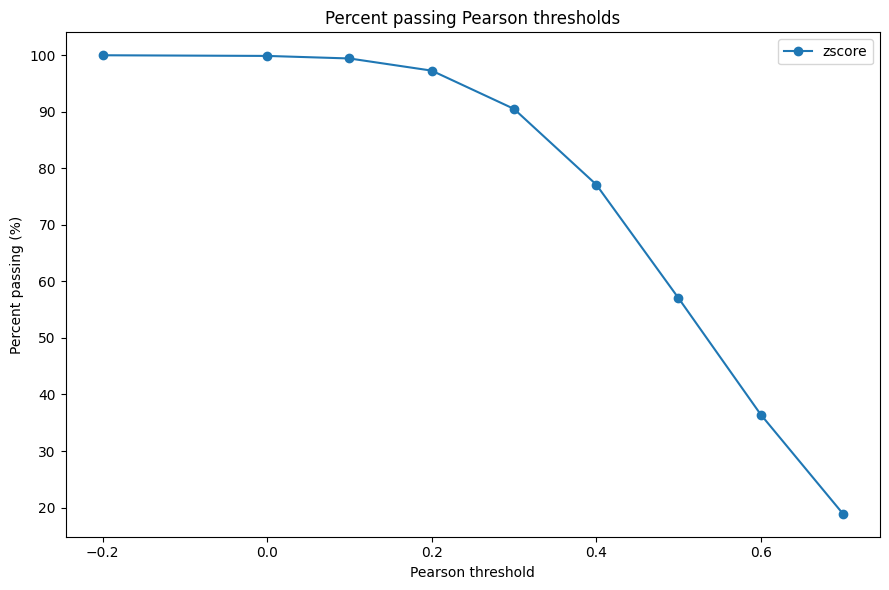

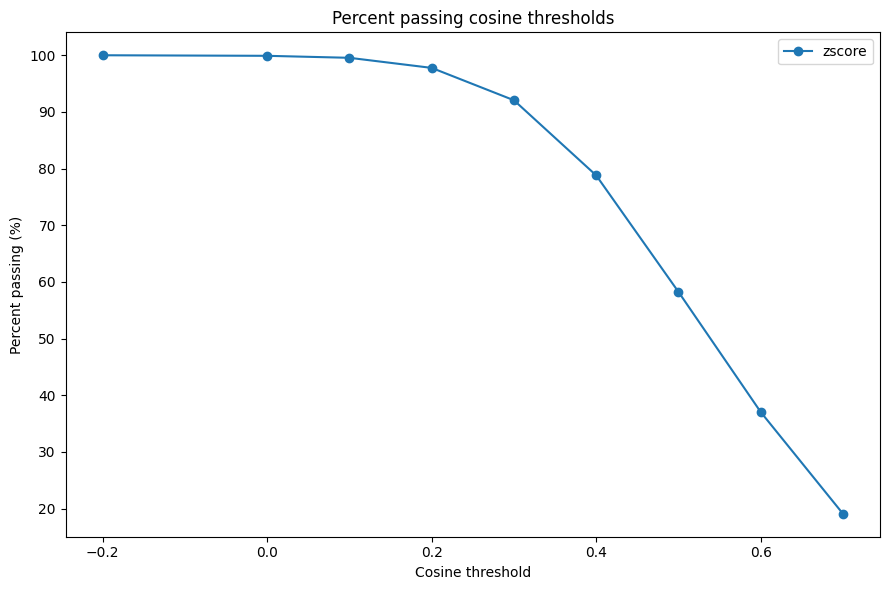

In [15]:
pearson_thresholds = [-0.2, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
cosine_thresholds = [-0.2, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

threshold_rows = []
for norm, sub in work.groupby("normalization"):
    n = len(sub)
    for t in pearson_thresholds:
        threshold_rows.append({
            "normalization": norm,
            "metric": "Pearson",
            "threshold": t,
            "count": int((sub["test_pearson_corr"] >= t).sum()),
            "percent": 100 * float((sub["test_pearson_corr"] >= t).mean()) if n else np.nan,
        })
    for t in cosine_thresholds:
        threshold_rows.append({
            "normalization": norm,
            "metric": "Cosine",
            "threshold": t,
            "count": int((sub["test_cosine_similarity"] >= t).sum()),
            "percent": 100 * float((sub["test_cosine_similarity"] >= t).mean()) if n else np.nan,
        })

threshold_curve = pd.DataFrame(threshold_rows)
display(threshold_curve.head())

plt.figure(figsize=(9, 6))
for norm, sub in threshold_curve[threshold_curve["metric"] == "Pearson"].groupby("normalization"):
    plt.plot(sub["threshold"], sub["percent"], marker="o", label=norm)
plt.title("Percent passing Pearson thresholds")
plt.xlabel("Pearson threshold")
plt.ylabel("Percent passing (%)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
for norm, sub in threshold_curve[threshold_curve["metric"] == "Cosine"].groupby("normalization"):
    plt.plot(sub["threshold"], sub["percent"], marker="o", label=norm)
plt.title("Percent passing cosine thresholds")
plt.xlabel("Cosine threshold")
plt.ylabel("Percent passing (%)")
plt.legend()
plt.tight_layout()
plt.show()

## Best normalization counts

This tells which normalization most often wins per protein.

### Normalization win counts

,best_by_pearson_count,best_by_score_count
normalization,,
zscore,5113,5113


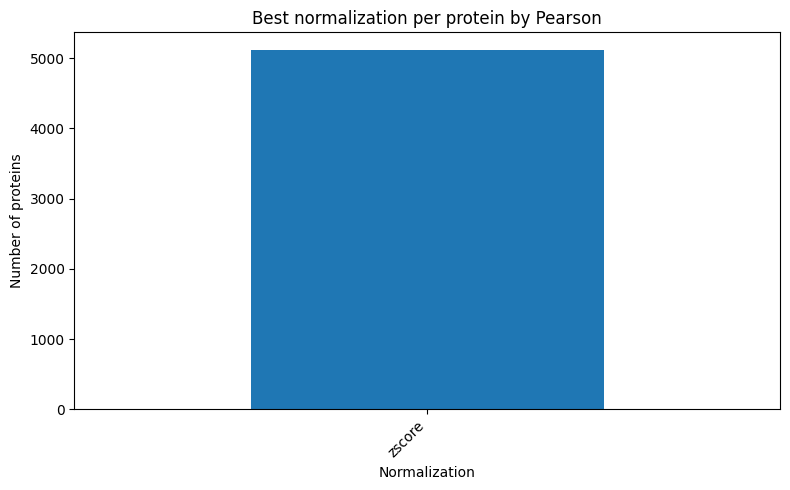

In [16]:
best_norm_counts_pearson = best_by_pearson["normalization"].value_counts().rename("best_by_pearson_count")
best_norm_counts_score = best_by_score["normalization"].value_counts().rename("best_by_score_count")
best_norm_counts = pd.concat([best_norm_counts_pearson, best_norm_counts_score], axis=1).fillna(0).astype(int)

display(Markdown("### Normalization win counts"))
display(best_norm_counts)

plt.figure(figsize=(8, 5))
best_norm_counts["best_by_pearson_count"].sort_values(ascending=False).plot(kind="bar")
plt.title("Best normalization per protein by Pearson")
plt.xlabel("Normalization")
plt.ylabel("Number of proteins")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Export analysis tables

This saves lightweight CSV summaries. It does **not** modify the H5 files.

In [17]:
ANALYSIS_DIR = RESULTS_DIR / "analysis_tables"
ANALYSIS_DIR.mkdir(exist_ok=True)

all_summary_path = ANALYSIS_DIR / "all_h5_metric_summary.csv"
best_pearson_path = ANALYSIS_DIR / "best_normalization_per_protein_by_pearson.csv"
best_score_path = ANALYSIS_DIR / "best_normalization_per_protein_by_balanced_score.csv"
threshold_path = ANALYSIS_DIR / "threshold_summary_by_normalization.csv"

work.to_csv(all_summary_path, index=False)
best_by_pearson[best_cols].to_csv(best_pearson_path, index=False)
best_by_score[best_cols].to_csv(best_score_path, index=False)
threshold_summary.to_csv(threshold_path)

print("Saved:")
print(" ", all_summary_path)
print(" ", best_pearson_path)
print(" ", best_score_path)
print(" ", threshold_path)

Saved:
  c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\results_xgb\analysis_tables\all_h5_metric_summary.csv
  c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\results_xgb\analysis_tables\best_normalization_per_protein_by_pearson.csv
  c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\results_xgb\analysis_tables\best_normalization_per_protein_by_balanced_score.csv
  c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\results_xgb\analysis_tables\threshold_summary_by_normalization.csv


## Inspect one saved model artifact

This loads **one** H5 file and its model artifact. Use this to verify selected features, best parameters, and model kind.

In [18]:
# Pick the best Pearson file by default.
if len(best_by_pearson) == 0:
    print("No best result available.")
else:
    example_path = Path(best_by_pearson.iloc[0]["h5_path"])
    print("Example H5 selected:", example_path)

    sys.path.insert(0, str(SRC_DIR))
    try:
        from functions import load_minimal_8020_h5, predict_with_artifact
        loaded = load_minimal_8020_h5(str(example_path))
        summary = loaded["summary"]
        artifact = loaded["model_artifact"]

        print("Protein:", summary.get("protein"))
        print("Test MSE:", summary.get("test_mse"))
        print("Test Pearson:", summary.get("test_pearson_corr"))
        print("Test cosine:", summary.get("test_cosine_similarity"))
        print("Train samples:", len(summary.get("train_samples", [])))
        print("Test samples:", len(summary.get("test_samples", [])))
        print("Selected features:", len(summary.get("selected_features", [])))
        print("Artifact kind:", artifact.get("artifact_kind"))
        print("Model class:", type(artifact.get("model")))
        print("First 20 selected features:")
        print(summary.get("selected_features", [])[:20])
        print("Best params:")
        print(json.dumps(summary.get("best_params", {}), indent=2))
    except Exception as e:
        print("Could not load model artifact:", repr(e))

Example H5 selected: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\new_pipeline_xgb\results_xgb\IGF2BP1_xgb_8020_zscore_current_k5000.h5
Could not load model artifact: ModuleNotFoundError("No module named 'numpy._core.numeric'")


c:\Users\hp\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [08:16:46] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\data\../common/error_msg.h:80: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  warnings.warn(smsg, UserWarning)


## Optional: predict from one saved model on a transcriptomics matrix

This cell demonstrates using the final all-samples model stored in the H5 file. It uses the current dataset by default, but you can change `X_PRED_PATH` to an external validation transcriptomics matrix with the same gene columns.

In [19]:
RUN_OPTIONAL_PREDICTION_DEMO = False
X_PRED_PATH = DATA_DIR / "transcriptomics_filtered.joblib"  # change this for external validation data

if RUN_OPTIONAL_PREDICTION_DEMO:
    from joblib import load
    from functions import load_minimal_8020_h5, predict_with_artifact

    example_path = Path(best_by_pearson.iloc[0]["h5_path"])
    loaded = load_minimal_8020_h5(str(example_path))
    artifact = loaded["model_artifact"]
    X_pred = load(X_PRED_PATH)

    pred = predict_with_artifact(artifact, X_pred)
    display(pred.head(20).to_frame("prediction"))
else:
    print("Optional prediction demo is disabled. Set RUN_OPTIONAL_PREDICTION_DEMO = True to run it.")

Optional prediction demo is disabled. Set RUN_OPTIONAL_PREDICTION_DEMO = True to run it.
